# XGBoost with NLP Features

## Overview

This notebook implements Twitter bot detection using **XGBoost** with both **structured features** and **NLP text features**.

### Features

**Structured Features** (from `process_data.py`):
- Numerical: followers_count, friends_count, statuses_count, etc.
- Binary: verified, default_profile, geo_enabled, etc.
- Categorical: lang (one-hot encoded)
- Textual patterns: description_has_url, screen_name_has_numbers, etc.
- Engineered: followers_per_day, followers_to_friends, profile_quality_score, etc.

**Text Features** (from `nlp.py`):
- **Word-level TF-IDF**: unigrams + bigrams (ngram_range=(1,2), max_features=30k-50k)
- **Character-level TF-IDF**: 3-5 char n-grams (ngram_range=(3,5), max_features=30k-50k)
- **TruncatedSVD**: dimensionality reduction (n_components=100-500)
- Combined from: `description`, `screen_name`, `location`

### Pipeline

1. **Data Loading**: Load train and test CSV files
2. **Text Extraction**: Combine text columns (description + screen_name + location)
3. **Cross-Validation**: 
   - Fit structured preprocessor on train fold → transform val fold
   - Fit text extractor on train fold → transform val fold
   - Concatenate structured + text features
   - Train XGBoost, evaluate on validation
4. **Hyperparameter Optimization**: 
   - Use Optuna to optimize XGBoost params + text feature params
   - Tune: n_estimators, max_depth, learning_rate, max_features_word, max_features_char, n_components
5. **Final Model**: Train on full dataset with best params
6. **Prediction**: Generate predictions for test set

### Key Implementation Details

✅ **Leakage Prevention**: TF-IDF + SVD fitted separately on each CV fold  
✅ **Reusable Components**: `TextFeatureExtractor` class in `helpers/nlp.py`  
✅ **Tunable Parameters**: Text feature params included in Optuna search  
✅ **Reproducibility**: Random seeds, saved models, saved text extractors  

### Files

- **Input**: `data/train.csv`, `data/test.csv`
- **Helpers**: `helpers/process_data.py`, `helpers/nlp.py`
- **Output**: `submissions/XGBoost_NLP_optuna.csv`
- **Models**: `trained/xgb_model_nlp_optuna.joblib`, `trained/text_extractor_optuna.joblib`

---

In [ ]:
import os
import sys
from IPython import get_ipython
import pandas as pd
import importlib

# Add parent directory to path to import from helpers
current_dir = os.getcwd()
parent_dir = os.path.abspath(os.path.join(current_dir, '..'))

# Only add if not already in path
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

import helpers.process_data
from helpers.process_data import process_data

# Import NLP helpers
import helpers.nlp
from helpers.nlp import TextFeatureExtractor, combine_text_columns

# Import NLP caching utilities for efficiency
import helpers.nlp_cache
from helpers.nlp_cache import get_or_create_text_features, clear_all_caches

import xgboost as xgb
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

In [2]:
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')


In [ ]:
# Data preparation - no preprocessing yet (done in CV to avoid leakage)
# Extract target from training data
y_train = train['target']

print("Data loaded:")
print(f"Training data shape: {train.shape}")
print(f"Test data shape: {test.shape}")
print("Target distribution:")
print(y_train.value_counts().sort_index())

print("\nTarget distribution percentages:")
target_counts = y_train.value_counts().sort_index()
for label, count in target_counts.items():
    percentage = (count / len(y_train)) * 100
    print(f"  Class {label}: {count:,} samples ({percentage:.1f}%)")

Data loaded:
Training data shape: (26206, 19)
Test data shape: (11232, 19)
Target distribution:
target
0    17423
1     8783
Name: count, dtype: int64

Target distribution percentages:
  Class 0: 17,423 samples (66.5%)
  Class 1: 8,783 samples (33.5%)


In [4]:
# NLP Feature Extraction Demo
print("="*70)
print("TEXT FEATURE EXTRACTION - DEMONSTRATION")
print("="*70)

# Combine text columns from multiple fields
print("\nCombining text columns: description, screen_name, location")
text_columns = ['description', 'screen_name', 'location']

train_text = combine_text_columns(train, columns=text_columns)
test_text = combine_text_columns(test, columns=text_columns)

print(f"Combined text shape: {train_text.shape}")
print(f"\nFirst 3 examples:")
for i in range(3):
    example_text = train_text.iloc[i][:100]
    print(f"  [{i}]: {example_text}...")

# Create text feature extractor with tunable parameters
print("\n" + "="*70)
print("Creating TextFeatureExtractor")
print("="*70)
print("Parameters:")
print("  - Word-level TF-IDF: max_features=30000, ngrams=(1,2)")
print("  - Char-level TF-IDF: max_features=30000, ngrams=(3,5)")
print("  - TruncatedSVD: n_components=300")

# This is a demo - we'll fit this properly in CV to avoid leakage
text_extractor_demo = TextFeatureExtractor(
    max_features_word=30000,
    max_features_char=30000,
    n_components=300,
    verbose=True
)

# Demo fit on small sample to show the pipeline
print("\n" + "="*70)
print("Demo: Fitting on first 1000 samples")
print("="*70)
sample_text = train_text.head(1000)
X_text_demo = text_extractor_demo.fit_transform(sample_text)

print(f"\nDemo output shape: {X_text_demo.shape}")
print(f"Feature names: {text_extractor_demo.get_feature_names()[:5]} ... {text_extractor_demo.get_feature_names()[-3:]}")
print("\nNote: In actual training, we'll fit separately on each CV fold to prevent data leakage!")

TEXT FEATURE EXTRACTION - DEMONSTRATION

Combining text columns: description, screen_name, location
Combined text shape: (26206,)

First 3 examples:
  [0]: Cosplayer/Fitness lover. Come to me https://t.co/8HhtbVhTdW reml5477 unknown...
  [1]: pobody’s nerfect kinlibra she/her ...
  [2]: gracias por participar 🏅 _delaualau La diaspora...

Creating TextFeatureExtractor
Parameters:
  - Word-level TF-IDF: max_features=30000, ngrams=(1,2)
  - Char-level TF-IDF: max_features=30000, ngrams=(3,5)
  - TruncatedSVD: n_components=300

Demo: Fitting on first 1000 samples
FITTING TEXT FEATURE EXTRACTOR
Number of texts: 1000

1. Fitting word-level TF-IDF (ngrams=(1, 2))...
   Word features shape: (1000, 1695)
   Vocabulary size: 1695

2. Fitting character-level TF-IDF (ngrams=(3, 5))...
   Char features shape: (1000, 26836)
   Vocabulary size: 26836

3. Concatenating word + char features...
   Combined features shape: (1000, 28531)

4. Fitting TruncatedSVD (n_components=300)...
   Char features shap

In [ ]:
# XGBoost with 5-fold Cross Validation - Preprocessing + NLP at each fold to avoid data leakage
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import numpy as np

# Initialize XGBoost classifier parameters
base_xgb_params = {
    'random_state': 42,
    'n_estimators': 100,
    'max_depth': 6,
    'learning_rate': 0.1,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'eval_metric': 'logloss'
}

# Text feature extraction parameters (tunable)
text_params = {
    'max_features_word': 30000,
    'max_features_char': 30000,
    'n_components': 300
}

print("=" * 70)
print("5-FOLD CROSS VALIDATION WITH STRUCTURED + TEXT FEATURES")
print("=" * 70)
print(f"\nText feature parameters:")
print(f"  Word TF-IDF max_features: {text_params['max_features_word']}")
print(f"  Char TF-IDF max_features: {text_params['max_features_char']}")
print(f"  SVD n_components: {text_params['n_components']}")

# Prepare raw data (without any preprocessing)
raw_train_features = train.drop('target', axis=1)
y_train = train['target']

# Prepare text data (combine columns once)
text_columns = ['description', 'screen_name', 'location']
train_text = combine_text_columns(train, columns=text_columns)

print(f"\nRaw training data shape: {raw_train_features.shape}")
print(f"Target shape: {y_train.shape}")
print(f"Combined text shape: {train_text.shape}")

# 5-fold stratified cross validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = []
fold_details = []
master_feature_list = None

print(f"\nStarting 5-fold cross validation...")

for fold, (train_idx, val_idx) in enumerate(skf.split(raw_train_features, y_train), 1):
    print(f"\n{'='*20} FOLD {fold}/5 {'='*20}")
    
    # Split raw data into train/validation for this fold
    raw_train_fold = raw_train_features.iloc[train_idx]
    raw_val_fold = raw_train_features.iloc[val_idx]
    y_train_fold = y_train.iloc[train_idx]
    y_val_fold = y_train.iloc[val_idx]
    
    # Split text data
    text_train_fold = train_text.iloc[train_idx]
    text_val_fold = train_text.iloc[val_idx]
    
    print(f"Raw train fold: {raw_train_fold.shape}, Raw val fold: {raw_val_fold.shape}")
    
    # ========== STRUCTURED FEATURES ==========
    print("Processing structured features...")
    X_train_fold_struct, fold_feature_list = process_data(
        raw_train_fold, verbose=False
    )
    
    # For the first fold, establish the master feature list
    if master_feature_list is None:
        master_feature_list = fold_feature_list.copy()
        print(f"  Established master feature list: {len(master_feature_list)} features")
    else:
        # Verify consistency with master list
        if set(fold_feature_list) != set(master_feature_list):
            # If different, use the master list for consistency
            print(f"  Feature list differs from master - enforcing consistency")
            X_train_fold_struct = process_data(
                raw_train_fold, verbose=False, expected_features=master_feature_list
            )
    
    # Process validation fold with master feature list to ensure consistency
    X_val_fold_struct = process_data(
        raw_val_fold, verbose=False, expected_features=master_feature_list
    )
    
    print(f"  Structured train: {X_train_fold_struct.shape}, val: {X_val_fold_struct.shape}")
    
    # ========== TEXT FEATURES ==========
    print("Extracting text features...")
    # Create fresh text extractor for this fold
    text_extractor_fold = TextFeatureExtractor(
        max_features_word=text_params['max_features_word'],
        max_features_char=text_params['max_features_char'],
        n_components=text_params['n_components'],
        verbose=False
    )
    
    # Fit on train fold, transform both train and val
    X_train_fold_text = text_extractor_fold.fit_transform(text_train_fold)
    X_val_fold_text = text_extractor_fold.transform(text_val_fold)
    
    print(f"  Text train: {X_train_fold_text.shape}, val: {X_val_fold_text.shape}")
    
    # ========== COMBINE FEATURES ==========
    print("Combining structured + text features...")
    X_train_fold = np.hstack([X_train_fold_struct.values, X_train_fold_text])
    X_val_fold = np.hstack([X_val_fold_struct.values, X_val_fold_text])
    
    print(f"  Combined train: {X_train_fold.shape}, val: {X_val_fold.shape}")
    
    # Train XGBoost on this fold
    print("Training XGBoost...")
    xgb_fold = xgb.XGBClassifier(**base_xgb_params)
    xgb_fold.fit(X_train_fold, y_train_fold)
    
    # Validate on this fold
    val_predictions = xgb_fold.predict(X_val_fold)
    fold_score = accuracy_score(y_val_fold, val_predictions)
    cv_scores.append(fold_score)
    
    print(f"Fold {fold} accuracy: {fold_score:.4f}")
    
    # Store fold details
    fold_details.append({
        'fold': fold,
        'train_size': len(y_train_fold),
        'val_size': len(y_val_fold),
        'accuracy': fold_score,
        'features_structured': X_train_fold_struct.shape[1],
        'features_text': X_train_fold_text.shape[1],
        'features_total': X_train_fold.shape[1]
    })

print(f"\n{'='*70}")
print("CROSS VALIDATION RESULTS")
print(f"{'='*70}")

cv_scores = np.array(cv_scores)
print(f"Individual fold scores: {cv_scores}")
print(f"Mean CV accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")
print(f"CV score range: {cv_scores.min():.4f} - {cv_scores.max():.4f}")
print(f"Standard deviation: {cv_scores.std():.4f}")

# Display fold details
print(f"\nFold Details:")
for detail in fold_details:
    print(f"  Fold {detail['fold']}: {detail['train_size']:,} train, {detail['val_size']:,} val")
    print(f"    Structured: {detail['features_structured']}, Text: {detail['features_text']}, "
          f"Total: {detail['features_total']}, Accuracy: {detail['accuracy']:.4f}")

print(f"\nMaster feature list established: {len(master_feature_list)} structured features")
print(f"All folds used consistent features")

# Now train final model on full dataset using the same preprocessing approach
print(f"\n{'='*70}")
print("TRAINING FINAL MODEL ON FULL DATASET")
print(f"{'='*70}")

# Process full training data with established feature list
print("Processing full training dataset (structured features)...")
X_train_final_struct, final_feature_list = process_data(raw_train_features, verbose=False)

# Ensure consistency with CV feature list
if set(final_feature_list) != set(master_feature_list):
    print("Final feature list differs from CV - enforcing CV consistency")
    X_train_final_struct = process_data(
        raw_train_features, verbose=False, expected_features=master_feature_list
    )
    final_feature_list = master_feature_list

print(f"  Structured features: {X_train_final_struct.shape}")

# Extract text features on full training data WITH CACHING FOR EFFICIENCY
print("Extracting text features on full training dataset (with caching)...")
print("Note: Caching is safe here - we're fitting on the FULL training set (no leakage)")

text_extractor_final, X_train_final_text, X_test_text_cache = get_or_create_text_features(
    train, test, text_columns, text_params, use_cache=True
)

print(f"  Text features: {X_train_final_text.shape}")

# Combine features
print("Combining structured + text features...")
X_train_final = np.hstack([X_train_final_struct.values, X_train_final_text])
print(f"  Combined features: {X_train_final.shape}")

print("\nTraining final XGBoost model...")
xgb_model = xgb.XGBClassifier(**base_xgb_params)
xgb_model.fit(X_train_final, y_train)

# Training accuracy
train_predictions = xgb_model.predict(X_train_final)
train_accuracy = accuracy_score(y_train, train_predictions)
print(f"Final model training accuracy: {train_accuracy:.4f}")

# Store variables for later use
X_train = X_train_final  # For compatibility with evaluation cell
feature_list = final_feature_list  # For test data processing (structured only)
text_extractor = text_extractor_final  # For test data processing (text features)

print("\nModel training complete with structured + text features!")

5-FOLD CROSS VALIDATION WITH STRUCTURED + TEXT FEATURES

Text feature parameters:
  Word TF-IDF max_features: 30000
  Char TF-IDF max_features: 30000
  SVD n_components: 300

Raw training data shape: (26206, 18)
Target shape: (26206,)
Combined text shape: (26206,)

Starting 5-fold cross validation...

==================== FOLD 1/5 ====================
Raw train fold: (20964, 18), Raw val fold: (5242, 18)
Processing structured features...
  Established master feature list: 80 features
  Structured train: (20964, 80), val: (5242, 80)
Extracting text features...
  Text train: (20964, 300), val: (5242, 300)
Combining structured + text features...
  Combined train: (20964, 380), val: (5242, 380)
Training XGBoost...
  Text train: (20964, 300), val: (5242, 300)
Combining structured + text features...
  Combined train: (20964, 380), val: (5242, 380)
Training XGBoost...
Fold 1 accuracy: 0.8844

==================== FOLD 2/5 ====================
Raw train fold: (20965, 18), Raw val fold: (5241, 

In [ ]:
# Generate predictions on test set with consistent preprocessing + text features
import joblib
import os

print("=" * 60)
print("GENERATING TEST PREDICTIONS (STRUCTURED + TEXT)")
print("=" * 60)

print("Processing test data with consistent feature list...")
print(f"Using feature list with {len(feature_list)} structured features from CV")

# Process structured features
X_test_struct = process_data(test, verbose=False, expected_features=feature_list)
print(f"  Structured test features: {X_test_struct.shape}")

# Use cached text features (already extracted during final model training)
print("Using cached text features from test data...")
X_test_text = X_test_text_cache
print(f"  Text test features: {X_test_text.shape}")

# Combine features
print("Combining structured + text features...")
X_test = np.hstack([X_test_struct.values, X_test_text])
print(f"  Combined test features: {X_test.shape}")

print(f"\nProcessed test data shape: {X_test.shape}")
print(f"Training data shape: {X_train.shape}")

# Verify consistency
print("\nConsistency check:")
print(f"Same number of columns: {X_train.shape[1] == X_test.shape[1]}")

if X_train.shape[1] == X_test.shape[1]:
    print("Perfect feature consistency between train and test")
else:
    print("✗ Feature inconsistency detected")

# Generate predictions
print("\nGenerating predictions on test set...")
test_probabilities = xgb_model.predict_proba(X_test)[:, 1]

# Create submission dataframe
submission = pd.DataFrame({
    'index': test['index'],
    'target': test_probabilities
})

# Save submission file to submissions folder
os.makedirs('../submissions', exist_ok=True)
submission_path = '../submissions/XGBoost_NLP.csv'
submission.to_csv(submission_path, index=False)

# Save trained model to models/trained folder
os.makedirs('trained', exist_ok=True)
model_path = 'trained/xgb_model_nlp.joblib'
joblib.dump(xgb_model, model_path)

# Save text extractor for reproducibility
text_extractor_path = 'trained/text_extractor.joblib'
joblib.dump(text_extractor, text_extractor_path)

print(f"\nSubmission file saved to: {submission_path}")
print(f"Trained model saved to: {model_path}")
print(f"Text extractor saved to: {text_extractor_path}")
print("\nPrediction statistics:")
print(f"  Range: {test_probabilities.min():.4f} to {test_probabilities.max():.4f}")
print(f"  Mean:  {test_probabilities.mean():.4f}")
print(f"  Std:   {test_probabilities.std():.4f}")
print(f"  Shape: {submission.shape}")

# Display first few predictions
print("\nFirst 10 predictions:")
print(submission.head(10))

GENERATING TEST PREDICTIONS (STRUCTURED + TEXT)
Processing test data with consistent feature list...
Using feature list with 80 structured features from CV
  Structured test features: (11232, 80)
Extracting text features from test data...
Transforming 11232 texts...
   Output shape: (11232, 300)
  Text test features: (11232, 300)
Combining structured + text features...
  Combined test features: (11232, 380)

Processed test data shape: (11232, 380)
Training data shape: (26206, 380)

Consistency check:
Same number of columns: True
✓ Perfect feature consistency between train and test

Generating predictions on test set...
   Output shape: (11232, 300)
  Text test features: (11232, 300)
Combining structured + text features...
  Combined test features: (11232, 380)

Processed test data shape: (11232, 380)
Training data shape: (26206, 380)

Consistency check:
Same number of columns: True
✓ Perfect feature consistency between train and test

Generating predictions on test set...

✓ Submission

In [7]:
# Comprehensive Model Evaluation
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

print("=" * 60)
print("COMPREHENSIVE MODEL EVALUATION")
print("=" * 60)

# Generate predictions and probabilities
train_pred_proba = xgb_model.predict_proba(X_train)[:, 1]
train_predictions = xgb_model.predict(X_train)

# 1. Classification Report
print("\n1. CLASSIFICATION REPORT (Training Data):")
print("-" * 40)
print(classification_report(y_train, train_predictions))

# 2. Confusion Matrix
print("2. CONFUSION MATRIX (Training Data):")
print("-" * 40)
cm = confusion_matrix(y_train, train_predictions)
print(f"Confusion Matrix:\n{cm}")

# Extract values for better interpretation
tn, fp, fn, tp = cm.ravel()
print("\nConfusion Matrix Breakdown:")
print(f"True Negatives (TN):  {tn:,}")
print(f"False Positives (FP): {fp:,}")
print(f"False Negatives (FN): {fn:,}")
print(f"True Positives (TP):  {tp:,}")

# 3. Additional Metrics
print("\n3. DETAILED METRICS:")
print("-" * 40)
from sklearn.metrics import precision_score, recall_score, f1_score

accuracy = accuracy_score(y_train, train_predictions)
precision = precision_score(y_train, train_predictions)
recall = recall_score(y_train, train_predictions)
f1 = f1_score(y_train, train_predictions)
roc_auc = roc_auc_score(y_train, train_pred_proba)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC AUC:   {roc_auc:.4f}")

# 4. Calculate Average Precision (PR AUC)
avg_precision = average_precision_score(y_train, train_pred_proba)
print(f"PR AUC:    {avg_precision:.4f}")

# 5. Class Distribution Analysis
print("\n4. CLASS DISTRIBUTION ANALYSIS:")
print("-" * 40)
class_counts = y_train.value_counts().sort_index()
print("True class distribution:")
for class_label, count in class_counts.items():
    percentage = (count / len(y_train)) * 100
    print(f"  Class {class_label}: {count:,} samples ({percentage:.1f}%)")

print("\nPredicted class distribution:")
pred_counts = pd.Series(train_predictions).value_counts().sort_index()
for class_label, count in pred_counts.items():
    percentage = (count / len(train_predictions)) * 100
    print(f"  Class {class_label}: {count:,} samples ({percentage:.1f}%)")

# 6. Probability Distribution Analysis
print("\n5. PROBABILITY DISTRIBUTION ANALYSIS:")
print("-" * 40)
print("Probability statistics:")
print(f"  Min probability:  {train_pred_proba.min():.4f}")
print(f"  Max probability:  {train_pred_proba.max():.4f}")
print(f"  Mean probability: {train_pred_proba.mean():.4f}")
print(f"  Std probability:  {train_pred_proba.std():.4f}")

# Analyze predictions by class
bot_probs = train_pred_proba[y_train == 1]
human_probs = train_pred_proba[y_train == 0]

print("\nProbability by true class:")
print(f"  Bots (Class 1) - Mean: {bot_probs.mean():.4f}, Std: {bot_probs.std():.4f}")
print(f"  Humans (Class 0) - Mean: {human_probs.mean():.4f}, Std: {human_probs.std():.4f}")

# 7. Model Performance Summary
print("\n6. MODEL PERFORMANCE SUMMARY:")
print("-" * 40)
print("Cross-Validation Performance:")
print(f"  Mean CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")
print(f"  CV Score Range: {cv_scores.min():.4f} - {cv_scores.max():.4f}")

print("\nTraining Performance:")
print(f"  Training Accuracy: {accuracy:.4f}")
print(f"  Training ROC AUC:  {roc_auc:.4f}")

# Check for potential overfitting
cv_mean = cv_scores.mean()
overfitting_diff = accuracy - cv_mean
print("\nOverfitting Check:")
print(f"  CV vs Train Accuracy Difference: {overfitting_diff:.4f}")
if overfitting_diff > 0.05:
    print("  Potential overfitting detected (difference > 0.05)")
elif overfitting_diff > 0.02:
    print("  Mild overfitting detected (difference > 0.02)")
else:
    print("  No significant overfitting detected")

print("\n" + "=" * 60)
print("EVALUATION COMPLETE")
print("=" * 60)

COMPREHENSIVE MODEL EVALUATION

1. CLASSIFICATION REPORT (Training Data):
----------------------------------------
              precision    recall  f1-score   support

           0       0.94      0.98      0.96     17423
           1       0.95      0.88      0.91      8783

    accuracy                           0.94     26206
   macro avg       0.95      0.93      0.94     26206
weighted avg       0.94      0.94      0.94     26206

2. CONFUSION MATRIX (Training Data):
----------------------------------------
Confusion Matrix:
[[17044   379]
 [ 1080  7703]]

Confusion Matrix Breakdown:
True Negatives (TN):  17,044
False Positives (FP): 379
False Negatives (FN): 1,080
True Positives (TP):  7,703

3. DETAILED METRICS:
----------------------------------------
Accuracy:  0.9443
Precision: 0.9531
Recall:    0.8770
F1-Score:  0.9135
ROC AUC:   0.9886
PR AUC:    0.9790

4. CLASS DISTRIBUTION ANALYSIS:
----------------------------------------
True class distribution:
  Class 0: 17,423 sam

Total features: 380
  Structured: 80
  Text (SVD): 300

Top 15 Most Important Features:
               feature  importance
       followers_count      0.0796
              verified      0.0374
     followers_per_day      0.0226
         friends_count      0.0189
           geo_enabled      0.0163
    verified_followers      0.0151
favourites_to_statuses      0.0146
     verified_statuses      0.0135
      favourites_count      0.0116
            text_svd_2      0.0110
      account_age_days      0.0104
 profile_image_url_len      0.0094
 profile_quality_score      0.0093
      statuses_per_day      0.0092
               lang_en      0.0088


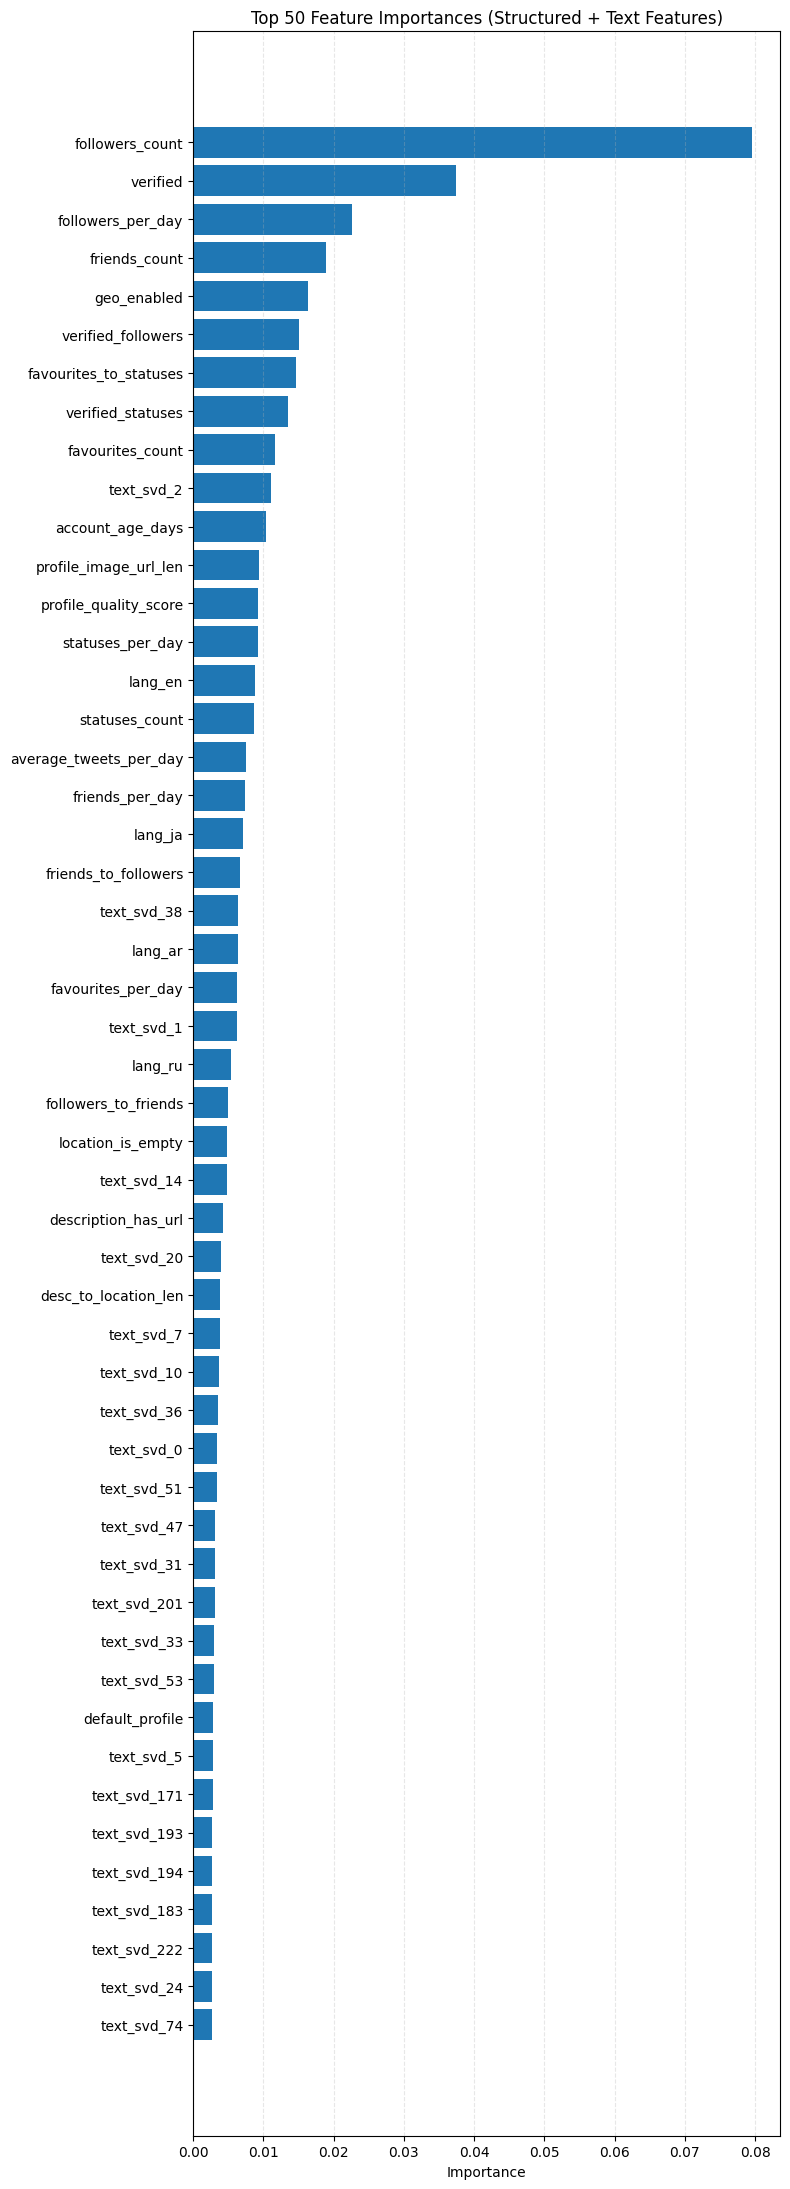


Top 50 Feature Breakdown:
  Structured features: 27
  Text features: 23

Text features contribute 46.0% of top 50 features


In [9]:
# Plot feature importances from the trained model
# Note: For combined structured + text features
import pandas as pd

# Create feature importance dataframe
feature_importance = xgb_model.feature_importances_
n_struct = len(feature_list)
n_text = X_train.shape[1] - n_struct

# Create feature names
struct_names = list(feature_list)
text_names = [f'text_svd_{i}' for i in range(n_text)]
all_feature_names = struct_names + text_names

importance_df = pd.DataFrame({
    'feature': all_feature_names,
    'importance': feature_importance
}).sort_values('importance', ascending=False)

print(f"Total features: {len(importance_df)}")
print(f"  Structured: {n_struct}")
print(f"  Text (SVD): {n_text}")
print(f"\nTop 15 Most Important Features:")
print(importance_df.head(15).to_string(index=False, float_format='%.4f'))

# Plot top N features as a horizontal bar chart
top_n = 50
top_df = importance_df.head(top_n).iloc[::-1]  # reverse for plotting

plt.figure(figsize=(8, 0.4 * len(top_df) + 2))
plt.barh(top_df['feature'], top_df['importance'], color='C0')
plt.xlabel('Importance')
plt.title(f'Top {top_n} Feature Importances (Structured + Text Features)')
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# Show breakdown of text vs structured features in top features
top_50_features = importance_df.head(50)
n_text_in_top50 = sum(top_50_features['feature'].str.startswith('text_svd_'))
n_struct_in_top50 = 50 - n_text_in_top50

print(f"\nTop 50 Feature Breakdown:")
print(f"  Structured features: {n_struct_in_top50}")
print(f"  Text features: {n_text_in_top50}")
print(f"\nText features contribute {n_text_in_top50/50*100:.1f}% of top 50 features")

# Hyperparameter Optimization

---

## 📖 Using the NLP Pipeline in Other Notebooks

The `TextFeatureExtractor` class is designed to be reusable across any model. Here's how to use it:

### Quick Start

```python
from helpers.nlp import TextFeatureExtractor, combine_text_columns
import numpy as np

# 1. Combine text columns
train_text = combine_text_columns(train, columns=['description', 'screen_name', 'location'])
test_text = combine_text_columns(test, columns=['description', 'screen_name', 'location'])

# 2. Create extractor
extractor = TextFeatureExtractor(
    max_features_word=30000,
    max_features_char=30000,
    n_components=300
)

# 3. Fit on training data
X_text_train = extractor.fit_transform(train_text)

# 4. Transform test data
X_text_test = extractor.transform(test_text)

# 5. Combine with structured features
X_train_combined = np.hstack([X_train_structured.values, X_text_train])
X_test_combined = np.hstack([X_test_structured.values, X_text_test])
```

### In Cross-Validation (Prevent Data Leakage!)

```python
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
    # Split data
    text_train_fold = train_text.iloc[train_idx]
    text_val_fold = train_text.iloc[val_idx]
    
    # Create NEW extractor for each fold
    extractor_fold = TextFeatureExtractor(n_components=300)
    
    # Fit on train fold, transform both
    X_text_train_fold = extractor_fold.fit_transform(text_train_fold)
    X_text_val_fold = extractor_fold.transform(text_val_fold)
    
    # Combine with structured features and train model
    # ...
```

### Tunable Parameters

Adjust these based on your data size and compute resources:

- `max_features_word`: 10000-50000 (word TF-IDF vocabulary size)
- `max_features_char`: 10000-50000 (char TF-IDF vocabulary size)
- `n_components`: 100-500 (SVD output dimensions)
- `min_df`: 2-5 (minimum document frequency to keep feature)
- `max_df`: 0.8-0.95 (maximum document frequency to keep feature)

### Compatible with Any Model

The output is a dense NumPy array, compatible with:
- ✅ XGBoost, LightGBM, CatBoost
- ✅ Random Forest, Extra Trees
- ✅ Logistic Regression, SVM
- ✅ Neural Networks (PyTorch, TensorFlow, Keras)

---

### Optuna new should be faster

In [ ]:
# Optuna imports and GPU check
import optuna
from optuna.samplers import TPESampler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import time
import warnings
import joblib
import os
warnings.filterwarnings('ignore', category=optuna.exceptions.ExperimentalWarning)

# Check for GPU availability
try:
    import GPUtil
    gpus = GPUtil.getGPUs()
    gpu_available = len(gpus) > 0
    if gpu_available:
        print(f"GPU detected: {gpus[0].name} with {gpus[0].memoryFree}MB free memory")
    else:
        print("No GPU detected, using CPU")
except ImportError:
    print("GPUtil not installed, assuming CPU usage")
    gpu_available = False

In [ ]:
# Define Optuna optimization function for XGBoost + NLP
def perform_optuna_xgboost_nlp_optimization(raw_train_features, y_train, n_trials=50, cv_folds=5, use_gpu=True):
    """
    Perform hyperparameter optimization for XGBoost using Optuna with:
    - Structured features (from process_data)
    - Text features (from TextFeatureExtractor) WITH CACHING
    - Fold-wise preprocessing to prevent data leakage
    
    Parameters:
    -----------
    raw_train_features : pd.DataFrame
        Raw training features (before preprocessing)
    y_train : pd.Series
        Training target
    n_trials : int, default=50
        Number of optimization trials
    cv_folds : int, default=5
        Number of cross-validation folds
    use_gpu : bool, default=True
        Whether to use GPU acceleration if available
    
    Returns:
    --------
    tuple : (best_model, best_params, best_score, study, X_train_full, feature_list_full, 
             importance_df_optuna, text_extractor_final, best_text_params)
    """
    
    print("="*70)
    print("OPTUNA HYPERPARAMETER OPTIMIZATION (XGBOOST + NLP)")
    print("="*70)
    print("\nOptimizing:")
    print("  - XGBoost hyperparameters (n_estimators, max_depth, learning_rate, etc.)")
    print("  - Text feature parameters (max_features_word, max_features_char, n_components)")
    print("\nPreprocessing happens within each CV fold to prevent data leakage.")
    print("Text features cached after final model training for speed!")
    
    # Determine tree method based on GPU availability
    if use_gpu and gpu_available:
        tree_method = 'gpu_hist'
        print(f"\nUsing GPU acceleration with tree_method='{tree_method}'")
    else:
        tree_method = 'hist'
        print(f"\nUsing CPU with tree_method='{tree_method}'")
    
    # Prepare text data once (doesn't need to be in fold loop)
    text_columns = ['description', 'screen_name', 'location']
    train_text = combine_text_columns(raw_train_features, columns=text_columns)
    
    # Setup cross-validation
    skf = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=42)
    
    print(f"\nOptimization Overview:")
    print(f"   Number of trials: {n_trials}")
    print(f"   Cross-validation folds: {cv_folds}")
    print(f"   Total model fits: {n_trials * cv_folds}")
    print(f"   Estimated time: {(n_trials * 45) / 60:.1f}-{(n_trials * 120) / 60:.1f} minutes\n")
    
    # Define objective function for Optuna
    def objective(trial):
        # Suggest XGBoost hyperparameters
        xgb_params = {
            'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
            'max_depth': trial.suggest_int('max_depth', 3, 10),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'min_child_weight': trial.suggest_int('min_child_weight', 1, 7),
            'gamma': trial.suggest_float('gamma', 0.0, 0.5),
            'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 1.0),
            'reg_lambda': trial.suggest_float('reg_lambda', 0.0, 1.0),
            'random_state': 42,
            'eval_metric': 'logloss',
            'tree_method': tree_method
        }
        
        if use_gpu and gpu_available:
            xgb_params['gpu_id'] = 0
        
        # Suggest text feature extraction hyperparameters
        text_params = {
            'max_features_word': trial.suggest_categorical('max_features_word', [10000, 20000, 30000, 50000]),
            'max_features_char': trial.suggest_categorical('max_features_char', [10000, 20000, 30000, 50000]),
            'n_components': trial.suggest_categorical('n_components', [100, 200, 300, 400, 500])
        }
        
        # Perform cross-validation with fold-wise preprocessing
        fold_scores = []
        master_feature_list = None
        
        for fold, (train_idx, val_idx) in enumerate(skf.split(raw_train_features, y_train), 1):
            # Split raw data
            raw_train_fold = raw_train_features.iloc[train_idx]
            raw_val_fold = raw_train_features.iloc[val_idx]
            y_train_fold = y_train.iloc[train_idx]
            y_val_fold = y_train.iloc[val_idx]
            
            # Split text data
            text_train_fold = train_text.iloc[train_idx]
            text_val_fold = train_text.iloc[val_idx]
            
            # ========== STRUCTURED FEATURES ==========
            X_train_fold_struct, fold_feature_list = process_data(raw_train_fold, verbose=False)
            
            # Establish or verify master feature list
            if master_feature_list is None:
                master_feature_list = fold_feature_list.copy()
            else:
                if set(fold_feature_list) != set(master_feature_list):
                    X_train_fold_struct = process_data(
                        raw_train_fold, verbose=False, expected_features=master_feature_list
                    )
            
            X_val_fold_struct = process_data(
                raw_val_fold, verbose=False, expected_features=master_feature_list
            )
            
            # ========== TEXT FEATURES (NO CACHING in CV - prevents leakage) ==========
            text_extractor_fold = TextFeatureExtractor(
                max_features_word=text_params['max_features_word'],
                max_features_char=text_params['max_features_char'],
                n_components=text_params['n_components'],
                verbose=False
            )
            
            X_train_fold_text = text_extractor_fold.fit_transform(text_train_fold)
            X_val_fold_text = text_extractor_fold.transform(text_val_fold)
            
            # ========== COMBINE FEATURES ==========
            X_train_fold = np.hstack([X_train_fold_struct.values, X_train_fold_text])
            X_val_fold = np.hstack([X_val_fold_struct.values, X_val_fold_text])
            
            # Train model
            model = xgb.XGBClassifier(**xgb_params)
            model.fit(X_train_fold, y_train_fold)
            
            # Validate
            val_predictions = model.predict(X_val_fold)
            fold_score = accuracy_score(y_val_fold, val_predictions)
            fold_scores.append(fold_score)
        
        # Return mean CV score
        mean_score = np.mean(fold_scores)
        return mean_score
    
    # Create Optuna study
    study = optuna.create_study(
        direction='maximize',
        sampler=TPESampler(seed=42)
    )
    
    # Run optimization
    print("Starting optimization...")
    start_time = time.time()
    
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
    
    total_time = time.time() - start_time
    
    # Get best parameters
    best_params = study.best_params
    best_score = study.best_value
    
    # Separate XGBoost and text params
    best_text_params = {
        'max_features_word': best_params['max_features_word'],
        'max_features_char': best_params['max_features_char'],
        'n_components': best_params['n_components']
    }
    
    best_xgb_params = {k: v for k, v in best_params.items() 
                       if k not in ['max_features_word', 'max_features_char', 'n_components']}
    
    print("\n" + "="*70)
    print("OPTIMIZATION COMPLETE!")
    print("="*70)
    print(f"\nTotal time: {total_time/60:.1f} minutes ({total_time:.0f} seconds)")
    print(f"Best Cross-Validation Score: {best_score:.4f}")
    
    print("\nBest XGBoost Parameters:")
    for param, value in best_xgb_params.items():
        print(f"   {param}: {value}")
    
    print("\nBest Text Feature Parameters:")
    for param, value in best_text_params.items():
        print(f"   {param}: {value}")
    
    # Train final model with best parameters on full dataset
    print("\n" + "="*70)
    print("TRAINING FINAL MODEL WITH BEST PARAMETERS")
    print("="*70)
    
    best_xgb_params_full = best_xgb_params.copy()
    best_xgb_params_full.update({
        'random_state': 42,
        'eval_metric': 'logloss',
        'tree_method': tree_method
    })
    if use_gpu and gpu_available:
        best_xgb_params_full['gpu_id'] = 0
    
    # Process full training data - structured features
    print("\nProcessing structured features on full training dataset...")
    X_train_full_struct, feature_list_full = process_data(raw_train_features, verbose=False)
    print(f"  Structured features: {X_train_full_struct.shape}")
    
    # Process full training data - text features WITH CACHING
    print("Extracting text features on full training dataset (with caching)...")
    print("Note: Caching is safe here - fitting on FULL training set after CV")
    
    text_extractor_final, X_train_full_text, _ = get_or_create_text_features(
        raw_train_features, test, text_columns, best_text_params, use_cache=True
    )
    
    print(f"  Text features: {X_train_full_text.shape}")
    
    # Combine features
    print("Combining structured + text features...")
    X_train_full = np.hstack([X_train_full_struct.values, X_train_full_text])
    print(f"  Combined features: {X_train_full.shape}")
    
    print("\nTraining final model...")
    best_model = xgb.XGBClassifier(**best_xgb_params_full)
    best_model.fit(X_train_full, y_train)
    
    # Training accuracy
    train_predictions = best_model.predict(X_train_full)
    train_accuracy = accuracy_score(y_train, train_predictions)
    print(f"Final model training accuracy: {train_accuracy:.4f}")
    
    # Feature importance
    feature_importance = best_model.feature_importances_
    n_struct = X_train_full_struct.shape[1]
    n_text = X_train_full_text.shape[1]
    
    struct_names = list(X_train_full_struct.columns)
    text_names = [f'text_svd_{i}' for i in range(n_text)]
    all_feature_names = struct_names + text_names
    
    importance_df_optuna = pd.DataFrame({
        'feature': all_feature_names,
        'importance': feature_importance
    }).sort_values('importance', ascending=False)
    
    print("\nTop 15 Most Important Features:")
    print(importance_df_optuna.head(15).to_string(index=False, float_format='%.4f'))
    
    # Optimization history analysis
    print("\n" + "="*70)
    print("OPTIMIZATION HISTORY ANALYSIS")
    print("="*70)
    
    trials_df = study.trials_dataframe()
    print(f"\nNumber of completed trials: {len(study.trials)}")
    print(f"Score range: {trials_df['value'].min():.4f} - {trials_df['value'].max():.4f}")
    print(f"Score std: {trials_df['value'].std():.4f}")
    print(f"Best trial number: {study.best_trial.number + 1}")
    
    # Show top 5 trials
    top_trials = trials_df.nlargest(5, 'value')[['value', 'number'] + 
                                                  [col for col in trials_df.columns if col.startswith('params_')]]
    print("\nTop 5 Trials:")
    print(top_trials.to_string(index=False, float_format='%.4f'))
    
    return (best_model, best_params, best_score, study, X_train_full, 
            feature_list_full, importance_df_optuna, text_extractor_final, best_text_params)

print("✓ Optuna optimization function defined with caching support")

In [ ]:
# Run Optuna optimization
optuna_results = perform_optuna_xgboost_nlp_optimization(
    raw_train_features=raw_train_features,
    y_train=y_train,
    n_trials=50,
    cv_folds=5,
    use_gpu=gpu_available
)

# Unpack results
(best_model_optuna, best_params_optuna, best_score_optuna, study_optuna, 
 X_train_full_optuna, feature_list_full_optuna, importance_df_optuna,
 text_extractor_optuna, best_text_params_optuna) = optuna_results

print("\n" + "="*70)
print("Optimization results unpacked and ready to use!")
print("="*70)

In [ ]:
# Generate predictions on test set using cached features
print("="*70)
print("GENERATING TEST PREDICTIONS (OPTUNA MODEL)")
print("="*70)

# Prepare test text data
text_columns = ['description', 'screen_name', 'location']
test_text = combine_text_columns(test, columns=text_columns)

# Process test data - structured features
print("\nProcessing structured features on test dataset...")
X_test_optuna_struct = process_data(test, verbose=False, expected_features=feature_list_full_optuna)
print(f"  Structured features: {X_test_optuna_struct.shape}")

# Load cached text features for test data (same cache as final model!)
print("Loading text features from cache...")
cache_key = get_cache_key(test_text, best_text_params_optuna)
_, X_test_optuna_text = load_text_features_cache(cache_key)

if X_test_optuna_text is None:
    print("ERROR: Test text features not found in cache!")
    print("This should have been created during final model training.")
    raise RuntimeError("Test text features cache missing")

print(f"  Text features: {X_test_optuna_text.shape}")

# Combine features
print("Combining structured + text features...")
X_test_optuna = np.hstack([X_test_optuna_struct.values, X_test_optuna_text])
print(f"  Combined features: {X_test_optuna.shape}")

# Generate predictions
print("\nGenerating predictions...")
test_predictions_optuna = best_model_optuna.predict(X_test_optuna)

# Create submission file
submission_optuna = pd.DataFrame({
    'id': test['id'],
    'target': test_predictions_optuna
})

# Save submission
submission_path_optuna = '/Users/winston/Documents/School/Y3S1/BT4012/Kaggle/Competition 1/submissions/XGBoost_NLP_optuna.csv'
submission_optuna.to_csv(submission_path_optuna, index=False)

print(f"\n✓ Predictions generated: {len(test_predictions_optuna)} samples")
print(f"✓ Submission saved to: {submission_path_optuna}")
print(f"✓ Bot predictions: {test_predictions_optuna.sum()}")
print(f"✓ Human predictions: {len(test_predictions_optuna) - test_predictions_optuna.sum()}")

# Save model and study
print("\nSaving trained model and Optuna study...")
joblib.dump(best_model_optuna, '/Users/winston/Documents/School/Y3S1/BT4012/Kaggle/Competition 1/models/trained/xgb_model_nlp_optuna.joblib')
joblib.dump(study_optuna, '/Users/winston/Documents/School/Y3S1/BT4012/Kaggle/Competition 1/models/trained/optuna_study_nlp.joblib')
joblib.dump(text_extractor_optuna, '/Users/winston/Documents/School/Y3S1/BT4012/Kaggle/Competition 1/models/trained/text_extractor_optuna.joblib')
print("✓ Model, study, and text extractor saved")

In [12]:
# Visualize Optuna optimization results
# Note: If you get nbformat errors, run: pip install --upgrade nbformat
import joblib
import optuna

# study_optuna = joblib.load('trained/optuna_study.joblib')
try:
    import plotly
    fig1 = optuna.visualization.plot_optimization_history(study_optuna)
    fig1.show()
    
    fig2 = optuna.visualization.plot_param_importances(study_optuna)
    fig2.show()
except Exception as e:
    print(f"Visualization error: {e}")
    print("\nTo fix this, run in terminal:")
    print("  pip install --upgrade nbformat plotly")
    print("\nAlternatively, you can view the optimization results as text:")
    print(f"\nBest trial: {study_optuna.best_trial.number}")
    print(f"Best value: {study_optuna.best_value:.4f}")
    print(f"Best params: {study_optuna.best_params}")


# Cleanup: Remove NLP Cache Files

Run this cell after completing all model training to free up disk space.

In [ ]:
# Clean up NLP cache files to free disk space
from helpers.nlp_cache import clear_all_caches

print("="*60)
print("CLEANING UP CACHE FILES")
print("="*60)

num_deleted = clear_all_caches()

print(f"\n✓ Cleanup complete! Removed {num_deleted} cache file(s)")
print("\nNote: Cache files speed up model training but can be safely deleted")
print("They will be regenerated automatically when needed.")